# Задача 10. Байесовская реконструкция энергии и вершины

1. Генерируем «наблюдённое» событие полной numpy-моделью (трассировка фотонов, затухание $L = 8$ м, пуассоновские ф.э. — задачи 3, 6): число ф.э. на каждом из 40 ФЭУ.
2. По этим числам восстанавливаем $E$ и $(x, y, z)$ методом NUTS в PyMC ([reconstruction.py](../src/reconstruction.py)).

## Правдоподобие
Фотоны рождаются по Пуассону со средним $YE$ и независимо попадают на катод $k$ с вероятностью $p_k(\vec x)$. Прореживание пуассоновского потока даёт **независимые** пуассоновские числа фотонов на катодах:
$$\mathrm{hits}_k \sim \mathrm{Poisson}(\lambda_k),\qquad \lambda_k(E, \vec x) = YE\,\frac{r^2\cos\psi_k}{4d_k^2}\,e^{-d_k/L}.$$
Каждый фотон даёт $\mathrm{Poisson}(a)$ ф.э., и после суммирования по ненаблюдаемому $\mathrm{hits}_k$ получаем распределение Неймана типа A:
$$P(\mathrm{pe}_k = m) = \sum_{h=0}^{h_{max}} \mathrm{Poisson}(h;\lambda_k)\,\mathrm{Poisson}(m; a h).$$
Сумма считается явно (через `logsumexp`), поэтому правдоподобие точное и дифференцируемо по $E$ и $\vec x$ — то, что нужно NUTS. Усечение суммы на $h_{max}$ на сэмплах постериора меняет $\log P$ меньше чем на $10^{-12}$; заметным оно становится только при $\lambda_k \gtrsim h_{max}$, где правдоподобие и так мало. Дискретные `hits` из модели исключены (маргинализованы), иначе NUTS неприменим. Отклик входит в модель как наблюдаемая величина: `pm.CustomDist('pe', lam, logp=..., random=..., observed=pe_obs)`.

**Приоры:** $E \sim U(0, 10)$ МэВ; вершина равномерна в шаре радиуса $r_{max} = 0.85R = 1.7$ м (фидуциальный объём).

## Что пришлось решить, чтобы NUTS работал
1. **Жёсткая стенка приора.** В первой версии $x, y, z \sim U(-r_{max}, r_{max})$ и точки вне шара отсекались (`Potential` $= -\infty$). На стенке плотность разрывна, и NUTS даёт расходящиеся траектории (300 на 8000 сэмплов, $\hat r = 1.03$). Теперь вершина задаётся без стенки: $\vec x = r_{max}\, s\, \vec v/|\vec v|$, где $\vec v \sim \mathcal N(0, I)$ — изотропное направление, а $s \sim \mathrm{Beta}(3, 1)$ имеет плотность $3s^2$ — ровно распределение $|\vec x|/r_{max}$ для точки, равномерной в шаре.
2. **Локальные максимумы у стенки.** Когда вершина вплотную подходит к какому-нибудь ФЭУ, на него приходится много света, и у правдоподобия появляются побочные максимумы с большой энергией. Они на ~25 единиц $\log$ ниже главного (т.е. в $e^{25}$ раз менее вероятны), но цепь, случайно стартовавшая рядом, оттуда не выходит: в первом прогоне серии событий в 9 из 40 случаев цепи сидели в разных максимумах ($\hat r$ до 1.8), и средняя восстановленная энергия была смещена на +10%. Поэтому цепи стартуют из MAP-точки, найденной `pm.find_MAP` из нескольких начальных приближений (центр и точки вдоль «центра тяжести» зарядов $\sum_k \mathrm{pe}_k\vec n_k$) — функция `start_point`.
3. **Фидуциальный объём.** У самой стенки ($\lesssim 3$ катодных радиусов до поверхности) приближение малого диска грубое, а $\lambda_k \propto 1/d_k^2$ меняется очень круто — NUTS снова расходится. С $r_{max} = 0.95R$ даже со стартом из MAP оставались события с десятками расхождений; с $r_{max} = 0.85R$ их мало: на событие обычно меньше 1%, ближе к стенке при 3 МэВ до 2.5%. Так поступают и в реальных детекторах: реконструкция надёжна только в фидуциальном объёме. События генерируем внутри $1.5$ м.

In [1]:
import sys
sys.path.insert(0, '../src')   # код проекта
import logging
logging.getLogger("pytensor.configdefaults").setLevel(logging.ERROR)   # нет компилятора C++, pytensor использует numba
import time
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from detector import Detector
from source import Source
from simulation import expected_fraction
from reconstruction import reconstruct
import warnings
warnings.filterwarnings("ignore", message="Numba will use object mode")   # random из CustomDist — обычная функция numpy
logging.getLogger("pymc").setLevel(logging.ERROR)   # без сообщений о каждом запуске сэмплера

Y = 10_000
det = Detector(R=2.0, N=40, r=0.10, a=0.5, attenuation_length=8.0, rng=10)
E_true = 1.5
x_true = np.array([0.5, -0.3, 0.8])

pe_obs = det.response(x_true, Source(Y=Y, rng=110).directions(E_true))
print("наблюдённые ф.э. по каналам:\n", pe_obs)
print("Q =", pe_obs.sum())

наблюдённые ф.э. по каналам:
 [12  3 17  3 10  5  2 12  1  4 13  2  4  2  1  3  2  4  6  2  5  2  3  4
  3  0  2  3  4  0  0  3  0  7  0  2  2  1  1  2]
Q = 152


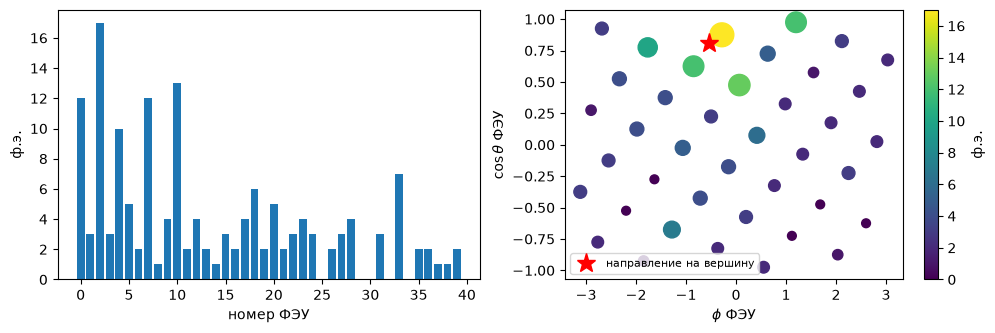

In [2]:
fig = plt.figure(figsize=(12, 3.5))
ax = fig.add_subplot(1, 2, 1)
ax.bar(np.arange(det.N), pe_obs); ax.set_xlabel('номер ФЭУ'); ax.set_ylabel('ф.э.')
ax = fig.add_subplot(1, 2, 2)
th = np.arccos(det.pmt_directions[:, 2]); ph = np.arctan2(det.pmt_directions[:, 1], det.pmt_directions[:, 0])
sc = ax.scatter(ph, np.cos(th), c=pe_obs, s=40 + 15 * pe_obs, cmap='viridis')
ax.plot(np.arctan2(x_true[1], x_true[0]), x_true[2] / np.linalg.norm(x_true), 'r*', ms=14, label='направление на вершину')
ax.set_xlabel(r'$\phi$ ФЭУ'); ax.set_ylabel(r'$\cos\theta$ ФЭУ'); ax.legend(fontsize=8)
plt.colorbar(sc, label='ф.э.'); plt.show()

## Модель и сэмплирование

In [3]:
t = time.perf_counter()
model, idata = reconstruct(det, Y, pe_obs, draws=2000, tune=1000, chains=4, seed=10)
print(f"MAP + NUTS: {time.perf_counter() - t:.0f} с, расхождений: {int(idata.sample_stats.diverging.sum())}")
az.summary(idata, var_names=['E', 'x', 'y', 'z', 'rho'], ci_prob=0.68)

There were 6 divergences after tuning. Increase `target_accept` or reparameterize.


MAP + NUTS: 28 с, расхождений: 6


,mean,sd,eti68_lb,eti68_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
E,1.548,0.15,1.4,1.7,4202,4047,1.00,0.0023,0.002
x,0.528,0.123,0.4,0.65,3911,4697,1.00,0.002,0.0015
y,-0.273,0.111,-0.38,-0.16,5400,5623,1.00,0.0015,0.0013
z,0.858,0.119,0.74,0.97,2888,1739,1.00,0.0022,0.0015
rho,1.057,0.114,0.94,1.2,2161,909,1.00,0.0024,0.0016


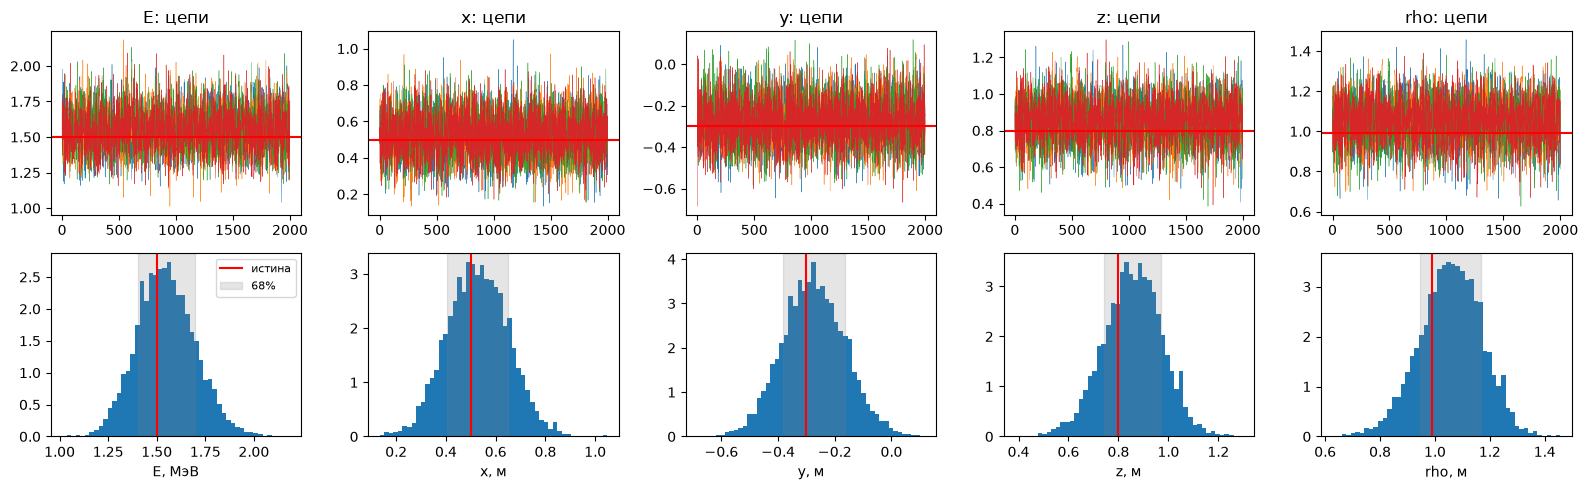

 пар.   истина   среднее ± σ        68% интервал       95% интервал    (среднее-истина)/σ
   E    1.500    1.548 ± 0.150   [ 1.404,  1.698]   [ 1.268,  1.851]   +0.32
   x    0.500    0.528 ± 0.123   [ 0.405,  0.650]   [ 0.294,  0.769]   +0.23
   y   -0.300   -0.273 ± 0.111   [-0.384, -0.163]   [-0.488, -0.052]   +0.24
   z    0.800    0.858 ± 0.119   [ 0.740,  0.972]   [ 0.615,  1.079]   +0.48
 rho    0.990    1.057 ± 0.114   [ 0.945,  1.169]   [ 0.826,  1.266]   +0.59

расстояние от реконструированной вершины до истинной: медиана 19 см


In [4]:
post = {v: idata.posterior[v].values.flatten() for v in ('E', 'x', 'y', 'z', 'rho')}
truth = dict(E=E_true, x=x_true[0], y=x_true[1], z=x_true[2], rho=np.linalg.norm(x_true))
units = dict(E='МэВ', x='м', y='м', z='м', rho='м')

fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for i, v in enumerate(post):
    for chain in idata.posterior[v].values:
        axes[0, i].plot(chain, lw=0.3)
    axes[0, i].axhline(truth[v], color='r'); axes[0, i].set_title(f'{v}: цепи')
    axes[1, i].hist(post[v], bins=50, density=True)
    axes[1, i].axvline(truth[v], color='r', label='истина')
    lo, hi = np.percentile(post[v], [16, 84])
    axes[1, i].axvspan(lo, hi, alpha=0.2, color='gray', label='68%')
    axes[1, i].set_xlabel(f'{v}, {units[v]}')
axes[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(" пар.   истина   среднее ± σ        68% интервал       95% интервал    (среднее-истина)/σ")
for v in post:
    m_, s_ = post[v].mean(), post[v].std()
    print(f"{v:>4s} {truth[v]:8.3f}  {m_:7.3f} ± {s_:.3f}   [{np.percentile(post[v], 16):6.3f}, {np.percentile(post[v], 84):6.3f}]"
          f"   [{np.percentile(post[v], 2.5):6.3f}, {np.percentile(post[v], 97.5):6.3f}]   {(m_ - truth[v]) / s_:+.2f}")
d = np.sqrt((post['x'] - x_true[0])**2 + (post['y'] - x_true[1])**2 + (post['z'] - x_true[2])**2)
print(f"\nрасстояние от реконструированной вершины до истинной: медиана {np.median(d)*100:.0f} см")

## Корреляции

Энергия и положение коррелированы: из-за затухания один и тот же заряд даёт событие меньшей энергии у стенки (меньше путь, меньше потерь) или большей — в центре.

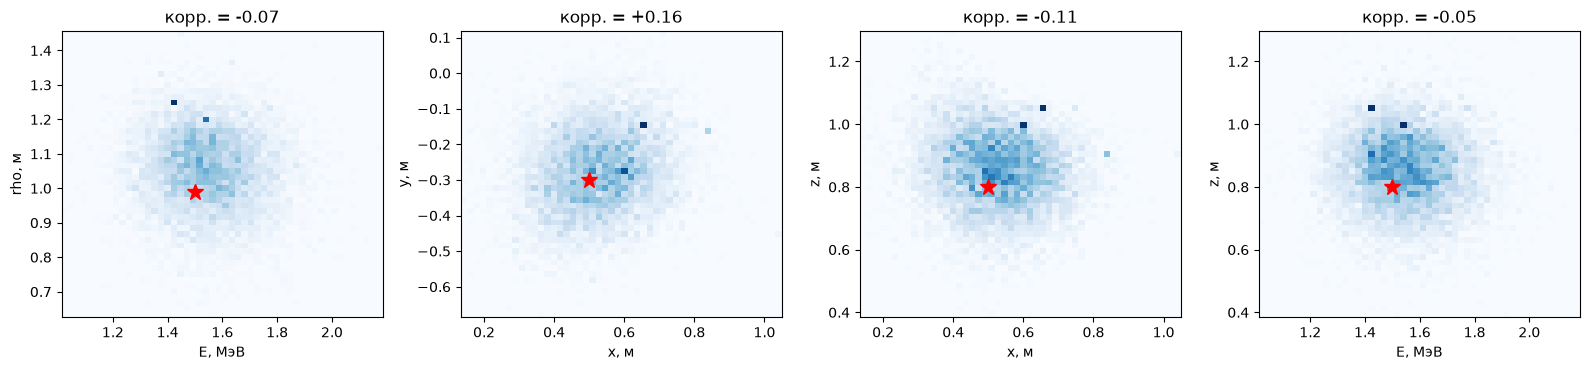

In [5]:
pairs = [('E', 'rho'), ('x', 'y'), ('x', 'z'), ('E', 'z')]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (a_, b_) in zip(axes, pairs):
    ax.hist2d(post[a_], post[b_], bins=50, cmap='Blues')
    ax.plot(truth[a_], truth[b_], 'r*', ms=12)
    ax.set_xlabel(f'{a_}, {units[a_]}'); ax.set_ylabel(f'{b_}, {units[b_]}')
    ax.set_title(f'корр. = {np.corrcoef(post[a_], post[b_])[0, 1]:+.2f}')
plt.tight_layout(); plt.show()

## Приор и постериор

Сэмплы приора — что известно до измерения: энергия равномерна до 10 МэВ, вершина где угодно в фидуциальном объёме.

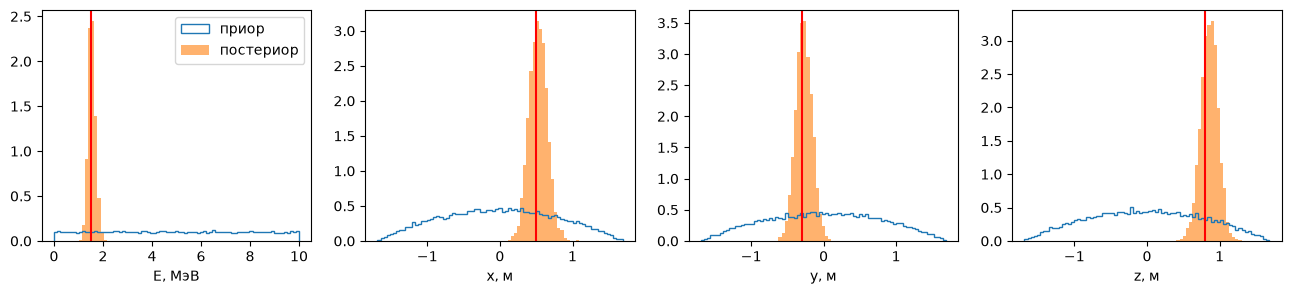

In [6]:
with model:
    prior = pm.sample_prior_predictive(20000, var_names=['E', 'x', 'y', 'z', 'rho'], random_seed=1).prior
prior = {v: prior[v].values.flatten() for v in post}
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, v in zip(axes, ('E', 'x', 'y', 'z')):
    bins = np.linspace(prior[v].min(), prior[v].max(), 80)
    ax.hist(prior[v], bins=bins, density=True, histtype='step', label='приор')
    ax.hist(post[v], bins=bins, density=True, alpha=0.6, label='постериор')
    ax.axvline(truth[v], color='r'); ax.set_xlabel(f'{v}, {units[v]}')
axes[0].legend(); plt.show()

## Проверка постериора по данным

Проверим, воспроизводит ли модель само наблюдение. Для каждого сэмпла постериора разыгрываем новый отклик (posterior predictive) и сравниваем его с наблюдённым по каналам и по полному заряду.

каналов внутри 95%-интервала предсказания: 100%
Q: наблюдение 152, предсказание 154.9 ± 21.2


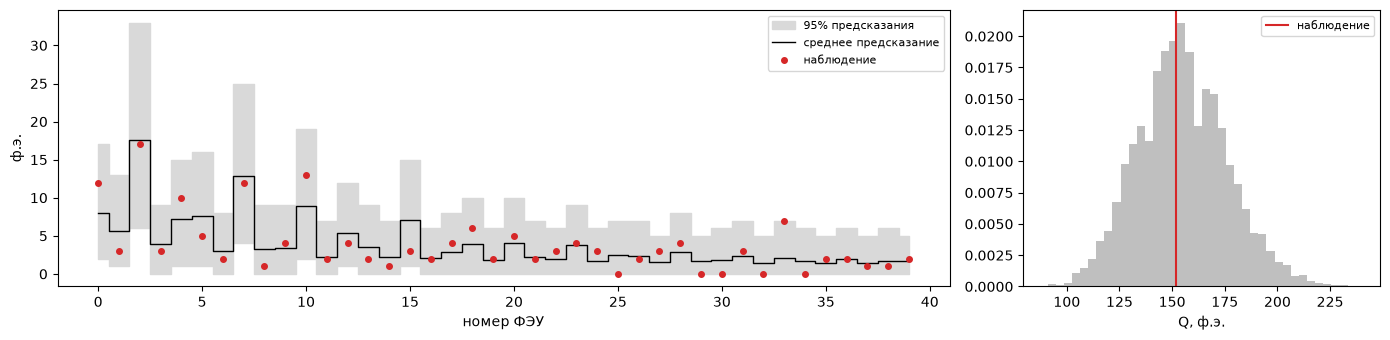

In [7]:
with model:
    ppc = pm.sample_posterior_predictive(idata, var_names=['pe'], random_seed=2, progressbar=False)
pe_pred = ppc.posterior_predictive['pe'].values.reshape(-1, det.N)
Q_pred = pe_pred.sum(axis=1)
lo, hi = np.percentile(pe_pred, [2.5, 97.5], axis=0)
inside = np.mean((pe_obs >= lo) & (pe_obs <= hi))
print(f"каналов внутри 95%-интервала предсказания: {inside:.0%}")
print(f"Q: наблюдение {pe_obs.sum()}, предсказание {Q_pred.mean():.1f} ± {Q_pred.std():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw=dict(width_ratios=[2.5, 1]))
ch = np.arange(det.N)
ax[0].fill_between(ch, lo, hi, step='mid', color='0.85', label='95% предсказания')
ax[0].plot(ch, pe_pred.mean(axis=0), 'k-', drawstyle='steps-mid', lw=1, label='среднее предсказание')
ax[0].plot(ch, pe_obs, 'o', ms=4, color='C3', label='наблюдение')
ax[0].set_xlabel('номер ФЭУ'); ax[0].set_ylabel('ф.э.'); ax[0].legend(fontsize=8)
ax[1].hist(Q_pred, bins=40, density=True, color='0.75')
ax[1].axvline(pe_obs.sum(), color='C3', label='наблюдение')
ax[1].set_xlabel('Q, ф.э.'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Точное правдоподобие против пуассоновского приближения

Если считать $\mathrm{pe}_k \sim \mathrm{Poisson}(a\lambda_k)$, теряются флуктуации числа ф.э. на фотон: дисперсия заряда $a\lambda$ вместо $a\lambda(1+a)$. Постериор от этого становится уже, чем допускают данные.

In [8]:
_, idata_p = reconstruct(det, Y, pe_obs, draws=2000, tune=1000, chains=4, seed=11, likelihood='poisson')
post_p = {v: idata_p.posterior[v].values.flatten() for v in post}
print(" пар.   Нейман A: среднее ± σ    Пуассон: среднее ± σ    σ_Пуассон / σ_Нейман")
for v in ('E', 'x', 'y', 'z'):
    print(f"{v:>4s}   {post[v].mean():7.3f} ± {post[v].std():.3f}       {post_p[v].mean():7.3f} ± {post_p[v].std():.3f}"
          f"        {post_p[v].std() / post[v].std():.2f}")
print(f"ожидаемое отношение 1/sqrt(1+a) = {1/np.sqrt(1 + det.a):.2f}")

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


 пар.   Нейман A: среднее ± σ    Пуассон: среднее ± σ    σ_Пуассон / σ_Нейман
   E     1.548 ± 0.150         1.530 ± 0.122        0.82
   x     0.528 ± 0.123         0.535 ± 0.103        0.84
   y    -0.273 ± 0.111        -0.277 ± 0.089        0.80
   z     0.858 ± 0.119         0.859 ± 0.095        0.80
ожидаемое отношение 1/sqrt(1+a) = 0.82


## Проверка на серии событий

Один постериор ничего не говорит о смещении и о правильности ширины. Восстановим 40 событий с $E = 1.5$ МэВ в случайных точках внутри шара радиуса 1.5 м и посмотрим на «пуллы» $(\langle\theta\rangle - \theta_{true})/\sigma_\theta$: при несмещённой реконструкции с правильной оценкой ошибок они распределены как $\mathcal N(0, 1)$, а истинное значение попадает в 68%-интервал в ~68% случаев. Цепи короткие (2 × 500 сэмплов); если они не сошлись ($\hat r > 1.03$), событие считается длинными (4 × 2000).

40 реконструкций: 664 с
сходимость: короткие цепи max r_hat = 1.155, пересчитано длинными цепями: 3 из 40;  итоговый max r_hat = 1.020;  доля расхождений: медиана 0.0%, максимум 0.8%
E: пулл = +0.07 ± 1.00,  истина в 68%-интервале: 62%,  в 95%: 98%
x: пулл = -0.15 ± 0.99,  истина в 68%-интервале: 62%,  в 95%: 100%
y: пулл = -0.32 ± 0.85,  истина в 68%-интервале: 75%,  в 95%: 98%
z: пулл = +0.10 ± 0.94,  истина в 68%-интервале: 70%,  в 95%: 95%


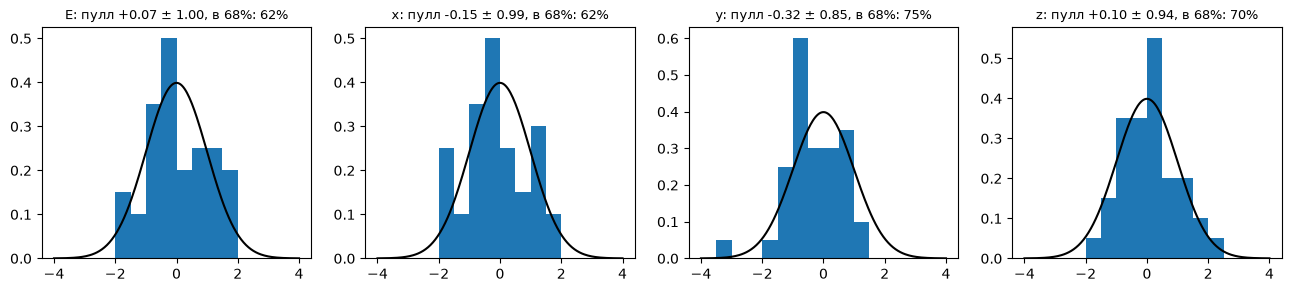

энергия: среднее восстановленное 1.523 МэВ (истина 1.5), σ_E/E = 10.3% (медиана);  разброс оценок 10.7%
вершина: σ по координате ≈ 11 см (медиана)
ожидаемое разрешение по заряду sqrt((1+a)/<Q>) = 10.1%


In [9]:
def rhat_of(idata):
    rh = az.rhat(idata, var_names=['E', 'x', 'y', 'z'])
    return max(float(rh[k]) for k in 'Exyz')

def fit_checked(pe, seed):
    """Короткие цепи; если они не сошлись (r_hat > 1.03), событие считается длинными."""
    _, idata = reconstruct(det, Y, pe, draws=500, tune=500, chains=2, seed=seed, compute_convergence_checks=False)
    r_short = rhat_of(idata)
    if r_short > 1.03:
        _, idata = reconstruct(det, Y, pe, draws=2000, tune=2000, chains=4, seed=seed, compute_convergence_checks=False)
    return idata, r_short, rhat_of(idata), float(idata.sample_stats.diverging.mean())

def convergence_report(fits):
    r_short, r_final, div = map(np.array, zip(*[f[1:] for f in fits]))
    print(f"сходимость: короткие цепи max r_hat = {r_short.max():.3f}, пересчитано длинными цепями: {np.sum(r_short > 1.03)} из {len(fits)};"
          f"  итоговый max r_hat = {r_final.max():.3f};  доля расхождений: медиана {np.median(div):.1%}, максимум {div.max():.1%}")

rng = np.random.default_rng(100)
n_ev = 40
rows, fits = [], []
t = time.perf_counter()
for i in range(n_ev):
    v = rng.normal(size=3); v /= np.linalg.norm(v)
    xt = v * 1.5 * rng.uniform() ** (1 / 3)
    pe = det.response(xt, Source(Y=Y, rng=1000 + i).directions(E_true))
    fit = fit_checked(pe, i)
    fits.append(fit)
    tr = fit[0].posterior
    s = {k: tr[k].values.flatten() for k in 'Exyz'}
    tv = dict(E=E_true, x=xt[0], y=xt[1], z=xt[2])
    rows.append({k: (s[k].mean(), s[k].std(), tv[k],
                     np.percentile(s[k], 16) <= tv[k] <= np.percentile(s[k], 84)) for k in 'Exyz'})
print(f"{n_ev} реконструкций: {time.perf_counter() - t:.0f} с")
convergence_report(fits)

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
g = np.linspace(-4, 4, 200)
for ax, k in zip(axes, 'Exyz'):
    pulls = np.array([(r[k][0] - r[k][2]) / r[k][1] for r in rows])
    cover = np.mean([r[k][3] for r in rows])
    ax.hist(pulls, bins=np.linspace(-4, 4, 17), density=True)
    ax.plot(g, np.exp(-g**2 / 2) / np.sqrt(2 * np.pi), 'k')
    ax.set_title(f'{k}: пулл {pulls.mean():+.2f} ± {pulls.std():.2f}, в 68%: {cover:.0%}', fontsize=9)
    print(f"{k}: пулл = {pulls.mean():+.2f} ± {pulls.std():.2f},  истина в 68%-интервале: {cover:.0%},  в 95%: {np.mean(np.abs(pulls) < 1.96):.0%}")
plt.show()

sig_E = np.array([r['E'][1] for r in rows]); mean_E = np.array([r['E'][0] for r in rows])
sig_pos = np.array([np.sqrt(r['x'][1]**2 + r['y'][1]**2 + r['z'][1]**2) / np.sqrt(3) for r in rows])
print(f"энергия: среднее восстановленное {mean_E.mean():.3f} МэВ (истина {E_true}), "
      f"σ_E/E = {np.median(sig_E) / E_true:.1%} (медиана);  разброс оценок {mean_E.std() / E_true:.1%}")
print(f"вершина: σ по координате ≈ {np.median(sig_pos) * 100:.0f} см (медиана)")
print(f"ожидаемое разрешение по заряду sqrt((1+a)/<Q>) = {np.sqrt((1 + det.a) / (det.a * Y * E_true * expected_fraction(det).sum())):.1%}")

## Проверка при большей энергии и ближе к стенке

Серия выше покрывает одну энергию и радиус до 1.5 м. Повторим её при $E = 3$ МэВ в шаре радиуса 1.65 м: заряд на ближнем катоде здесь больше, а приближение малого диска грубее (при 1.7 м под катодом оно завышает долю света на этом канале на 8.5%).

In [10]:
rng = np.random.default_rng(300)
E_hi, n_hi = 3.0, 30
rows_hi, fits_hi = [], []
for i in range(n_hi):
    v = rng.normal(size=3); v /= np.linalg.norm(v)
    xt = v * 1.65 * rng.uniform() ** (1 / 3)
    pe = det.response(xt, Source(Y=Y, rng=3000 + i).directions(E_hi))
    fit = fit_checked(pe, i)
    fits_hi.append(fit)
    s = {k: fit[0].posterior[k].values.flatten() for k in 'Exyz'}
    tv = dict(E=E_hi, x=xt[0], y=xt[1], z=xt[2])
    rows_hi.append({k: (s[k].mean(), s[k].std(), tv[k]) for k in 'Exyz'})
convergence_report(fits_hi)
for k in 'Exyz':
    pulls = np.array([(r[k][0] - r[k][2]) / r[k][1] for r in rows_hi])
    print(f"{k}: пулл = {pulls.mean():+.2f} ± {pulls.std():.2f},  в 68%: {np.mean(np.abs(pulls) < 1):.0%},  в 95%: {np.mean(np.abs(pulls) < 1.96):.0%}")
mean_hi = np.array([r['E'][0] for r in rows_hi])
print(f"энергия: среднее восстановленное {mean_hi.mean():.3f} ± {mean_hi.std() / np.sqrt(n_hi):.3f} МэВ (истина {E_hi})")

сходимость: короткие цепи max r_hat = 1.018, пересчитано длинными цепями: 0 из 30;  итоговый max r_hat = 1.018;  доля расхождений: медиана 0.1%, максимум 2.5%
E: пулл = +0.17 ± 0.90,  в 68%: 63%,  в 95%: 100%
x: пулл = -0.56 ± 1.12,  в 68%: 63%,  в 95%: 90%
y: пулл = -0.15 ± 0.96,  в 68%: 73%,  в 95%: 97%
z: пулл = +0.04 ± 1.15,  в 68%: 57%,  в 95%: 93%
энергия: среднее восстановленное 3.044 ± 0.037 МэВ (истина 3.0)


**Выводы.**
- **Одно событие** ($E = 1.5$ МэВ, $\vec x = (0.5, -0.3, 0.8)$ м, $Q = 152$ ф.э.): $E = 1.55 \pm 0.15$ МэВ, $\vec x = (0.53, -0.27, 0.86) \pm 0.12$ м. $E$ и все координаты в пределах $0.5\sigma$ от истины, вершина восстановлена с точностью ~19 см. Сходимость хорошая: $\hat r = 1.00$, эффективный размер выборки от ~2900, 6 расхождений на 8000 сэмплов.
- **Серия из 40 событий:** средняя восстановленная энергия $1.523 \pm 0.025$ МэВ при истинной 1.5 — смещения нет. Пуллы $E, x, y, z$: ширина 0.85–1.00 ≈ 1; истина попадает в 68%-интервал в 62–75% случаев (ожидание 68%, статистическая погрешность при 40 событиях ±7%), в 95%-интервал — в 95–100%. То есть постериор правильно оценивает и само значение, и его неопределённость. Самое большое среднее у $y$: $-0.32 \pm 0.13$; в отдельной серии с другими seed оно равно $-0.08 \pm 0.15$. Короткие цепи не сошлись в 3 событиях из 40 ($\hat r$ до 1.155). Длинные цепи дали итоговый $\hat r \le 1.02$.
- **3 МэВ, радиус до 1.65 м (30 событий):** энергия $3.044 \pm 0.037$ МэВ, ширина пуллов 0.90–1.15, в 68%-интервал попадает 57–73% случаев. Самое большое среднее у $x$: $-0.56 \pm 0.20$; в отдельной серии из 40 событий с другими seed оно равно $-0.18 \pm 0.15$, так что смещения по этой оси нет. Приближение малого диска у стенки смещения тоже не даёт: на 16 событиях в 1.6 м под катодом оно и точный интеграл по диску дают $E = 3.02 \pm 0.05$ и $3.03 \pm 0.05$ МэВ. Расхождения здесь остаются и на длинных цепях (до 1.6% в отдельной серии), но средние при этом не меняются.
- **Проверка по данным:** posterior predictive воспроизводит наблюдение: все каналы лежат внутри 95%-интервала предсказания, а $Q = 152$ при предсказании $154.9 \pm 21.2$.
- **Разрешение:** $\sigma_E/E \approx 10\%$ при 1.5 МэВ — совпадает с пределом $\sqrt{(1+a)/\langle Q\rangle} = 10.1\%$, задаваемым статистикой фотоэлектронов (задача 4). Неизвестное положение вершины разрешение почти не ухудшает: 40 каналов несут достаточно информации, чтобы определить вершину с точностью ~11 см по каждой координате.
- **Правдоподобие важно:** пуассоновское приближение $\mathrm{pe}_k \sim \mathrm{Poisson}(a\lambda_k)$ сужает постериор в $0.8 \approx 1/\sqrt{1+a}$ раза, т.е. ошибки получились бы заниженными на 20%. Точное распределение Неймана типа A учитывает флуктуации числа ф.э. на фотон.
- **Практические уроки MCMC:** (1) приор без разрывов (параметризация шара через $\mathrm{Beta}(3,1)$ вместо отсечения), (2) старт цепей из MAP — иначе цепи застревают в побочных максимумах у стенки, что давало смещение энергии на +10% и $\hat r$ до 1.8, (3) фидуциальный объём $0.85R$, где модель правдоподобия надёжна. Без этих мер реконструкция выглядела бы правдоподобно на отдельном событии, но была бы смещена на серии — поэтому её обязательно проверять по пуллам.